In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

sys.path.insert(0, str(Path("../src").resolve()))
%load_ext autoreload
%autoreload 2
from uplift.metrics import qini_auc, qini_curve, bootstrap_qini, calibration_table

DATA = Path("../data/processed")
FIG = Path("../reports/figures")

# Nur das Testset wird gebraucht: Outcome, Treatment und die gespeicherten Vorhersagen aus Notebook 03
df = pd.read_parquet(DATA / "criteo_uplift_v2.1.parquet", columns=["treatment", "visit"])
split = pd.read_parquet(DATA / "split.parquet")["split"].to_numpy()
te = df[split == 2]
del df
preds = pd.read_parquet(DATA / "preds_test.parquet")
assert preds.index.equals(te.index)   # gleiche Zeilen in gleicher Reihenfolge
y_te, w_te = te["visit"].to_numpy(), te["treatment"].to_numpy()

MODELS = list(preds.columns)
UPLIFT_MODELS = [m for m in MODELS if m not in ("random", "response")]
print(MODELS)

['random', 'response', 's_learner', 't_learner', 'x_learner', 'dr_learner', 'causal_forest']


In [2]:
# Punktschätzer zur Kontrolle – müssen mit reports/model_comparison.csv übereinstimmen
point = pd.Series({m: qini_auc(y_te, w_te, preds[m]) for m in MODELS}, name="qini_auc")
point.round(4)

random          -0.0044
response         0.3413
s_learner        0.3595
t_learner        0.3280
x_learner        0.3594
dr_learner       0.3600
causal_forest    0.3559
Name: qini_auc, dtype: float64

In [3]:
# 200 Bootstrap-Runden des Testsets (Poisson-Gewichte, gepaart über alle Modelle), dauert ca. 4–5 Minuten
# Erfasst nur die Unsicherheit durch das Testset, nicht die durch das Training
boot, boot_curves = bootstrap_qini(y_te, w_te, {m: preds[m].to_numpy() for m in MODELS}, n_boot=200, seed=0)

ci = pd.DataFrame({"qini_auc": point,
                   "ci_low": boot.quantile(0.025), "ci_high": boot.quantile(0.975),
                   "sd": boot.std()})
ci.round(4)

,qini_auc,ci_low,ci_high,sd
random,-0.0044,-0.0210,0.0140,0.0088
response,0.3413,0.3317,0.3524,0.0053
s_learner,0.3595,0.3411,0.3758,0.0086
t_learner,0.3280,0.3077,0.3488,0.0109
x_learner,0.3594,0.3421,0.3797,0.0095
dr_learner,0.3600,0.3436,0.3794,0.0096
causal_forest,0.3559,0.3452,0.3693,0.0063


In [4]:
# Gepaarte Differenzen: in jeder Runde bekommen alle Modelle dieselbe Stichprobe.
# Gemeinsame Schwankungen (z. B. "zufällig viele Visits in der Treatment-Gruppe") heben sich auf,
# daher ist das Intervall der Differenz viel enger, als die Einzelintervalle vermuten lassen
def paired_diff(ref):
    d = boot.sub(boot[ref], axis=0).drop(columns=ref)
    return pd.DataFrame({"diff": point.drop(ref) - point[ref],
                         "ci_low": d.quantile(0.025), "ci_high": d.quantile(0.975),
                         "p_besser": (d > 0).mean()})   # Anteil der Runden, in denen das Modell vorne liegt

print("Gegenüber dem Response-Modell:")
display(paired_diff("response").round(4))
print("Gegenüber dem S-Learner:")
display(paired_diff("s_learner").round(4))

Gegenüber dem Response-Modell:


,diff,ci_low,ci_high,p_besser
random,-0.3457,-0.3641,-0.3248,0.000
s_learner,0.0181,0.0032,0.0330,0.995
t_learner,-0.0133,-0.0367,0.0082,0.105
x_learner,0.0181,0.0017,0.0364,0.985
dr_learner,0.0187,0.0003,0.0360,0.980
causal_forest,0.0146,0.0047,0.0272,0.995


Gegenüber dem S-Learner:


,diff,ci_low,ci_high,p_besser
random,-0.3639,-0.3844,-0.3375,0.000
response,-0.0181,-0.0330,-0.0032,0.005
t_learner,-0.0314,-0.0504,-0.0116,0.000
x_learner,-0.0000,-0.0154,0.0133,0.570
dr_learner,0.0006,-0.0153,0.0177,0.570
causal_forest,-0.0035,-0.0185,0.0095,0.425


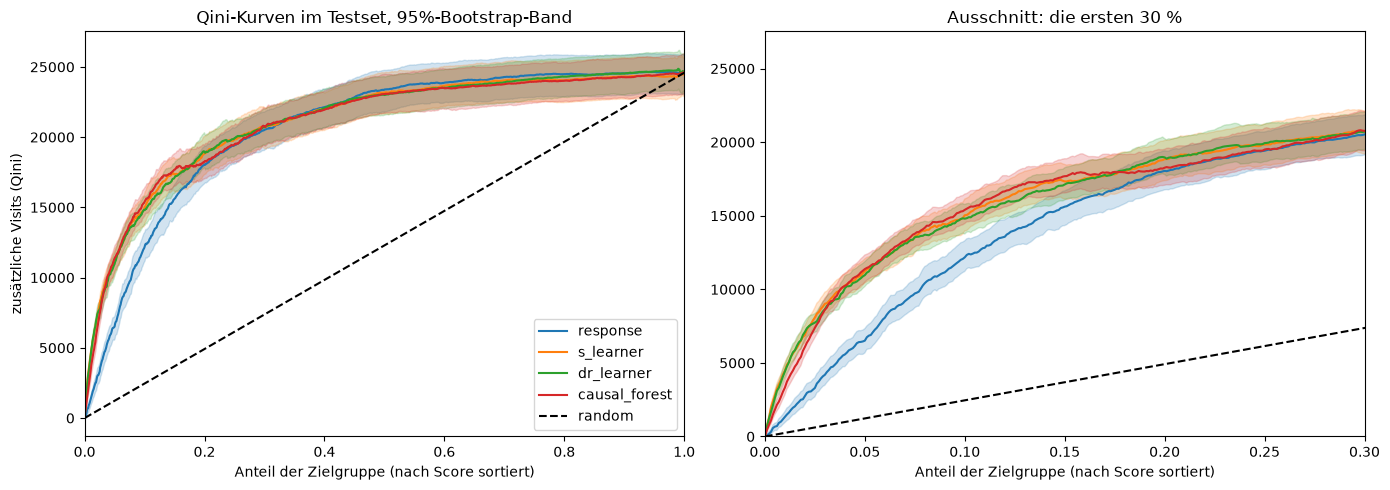

In [5]:
# Qini-Kurven mit punktweisem 95%-Band (Perzentile über die Bootstrap-Runden)
grid = np.linspace(0, 1, 1001)   # Raster, auf dem bootstrap_qini die Kurven ablegt
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, xmax in zip(axes, (1.0, 0.3)):   # rechts: Ausschnitt der ersten 30 %
    for m in ["response", "s_learner", "dr_learner", "causal_forest"]:
        frac, q = qini_curve(y_te, w_te, preds[m])
        line, = ax.plot(frac, q, label=m)
        lo, hi = np.percentile(boot_curves[m], [2.5, 97.5], axis=0)
        ax.fill_between(grid, lo, hi, color=line.get_color(), alpha=0.2)
    ax.plot([0, 1], [0, q[-1]], "k--", label="random")
    ax.set_xlim(0, xmax)
    ax.set_xlabel("Anteil der Zielgruppe (nach Score sortiert)")
axes[1].set_ylim(0, None)
axes[0].set_ylabel("zusätzliche Visits (Qini)")
axes[0].set_title("Qini-Kurven im Testset, 95%-Bootstrap-Band")
axes[1].set_title("Ausschnitt: die ersten 30 %")
axes[0].legend()
fig.tight_layout()
fig.savefig(FIG / "qini_bootstrap.png", dpi=120)

In [6]:
# Kalibrierung: 10 gleich große Gruppen nach vorhergesagtem Uplift (0 = höchster)
# Vergleich mittlere Vorhersage vs. beobachteter Uplift (Rate_T − Rate_C) in derselben Gruppe
# Das Response-Modell fehlt: es sagt P(visit) vorher, keinen Uplift
calib = {m: calibration_table(y_te, w_te, preds[m]) for m in UPLIFT_MODELS}
pd.concat({m: t[["predicted", "observed"]] for m, t in calib.items()}, axis=1).round(4)

s_learner          t_learner          x_learner          dr_learner  \
      predicted observed predicted observed predicted observed  predicted   
group                                                                       
0        0.0611   0.0621    0.0667   0.0583    0.0567   0.0615     0.0485   
1        0.0083   0.0072    0.0093   0.0063    0.0069   0.0075     0.0069   
2        0.0024   0.0014    0.0023   0.0022    0.0028   0.0023     0.0030   
3        0.0010   0.0008    0.0009   0.0008    0.0017   0.0005     0.0023   
4        0.0005   0.0008    0.0005   0.0008    0.0011   0.0013     0.0017   
5        0.0003   0.0004    0.0003   0.0005    0.0009   0.0009     0.0017   
6        0.0002   0.0007    0.0001   0.0003    0.0008   0.0000     0.0017   
7        0.0001  -0.0002    0.0000   0.0005    0.0008   0.0006     0.0017   
8        0.0001   0.0006   -0.0001   0.0004    0.0008   0.0003     0.0017   
9       -0.0005   0.0010   -0.0059   0.0061    0.0000   0.0009     0.0013   

               causal_forest           
      observed     predicted observed  
group                                  
0       0.0611        0.0463   0.0636  
1       0.0109        0.0094   0.0073  
2       0.0013        0.0047   0.0065  
3       0.0017        0.0022   0.0010  
4       0.0014        0.0012   0.0010  
5       0.0008        0.0008   0.0002  
6       0.0005        0.0006   0.0001  
7       0.0004        0.0004   0.0003  
8       0.0003        0.0002   0.0006  
9       0.0003       -0.0003   0.0007

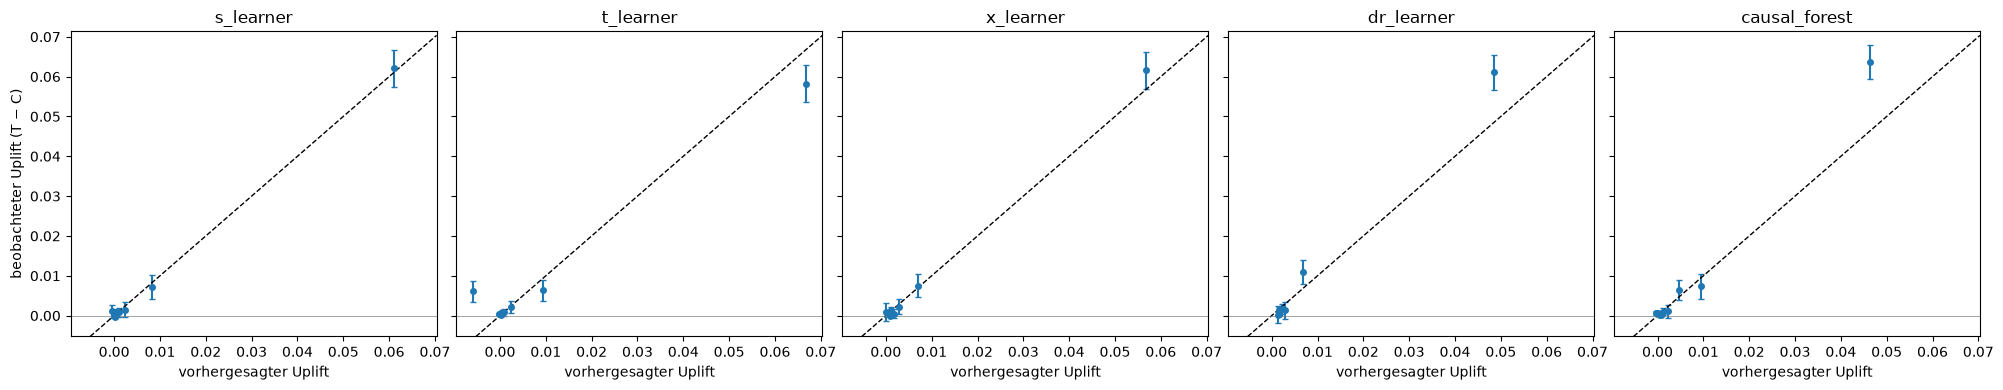

In [7]:
# Kalibrierungsdiagramm: Punkte auf der Diagonale = Vorhersage stimmt im Mittel; Fehlerbalken = 95%-KI
fig, axes = plt.subplots(1, len(calib), figsize=(4 * len(calib), 4), sharex=True, sharey=True)
for ax, (m, t) in zip(axes, calib.items()):
    ax.errorbar(t["predicted"], t["observed"], yerr=1.96 * t["se"], fmt="o", ms=4, capsize=2)
    ax.axline((0, 0), slope=1, color="k", ls="--", lw=1)
    ax.axhline(0, color="grey", lw=0.5)
    ax.set_title(m)
    ax.set_xlabel("vorhergesagter Uplift")
axes[0].set_ylabel("beobachteter Uplift (T − C)")
fig.tight_layout()
fig.savefig(FIG / "calibration.png", dpi=120)

In [8]:
# Kalibrierung im Mittel: alle Modelle sagen im Schnitt ~0,007 vorher, die Differenz der Mittelwerte ist ~0,010.
# Gegenprobe: dieselbe Differenz innerhalb von 100 gleich großen Gruppen nach Response-Score (≈ Grundrate) bilden und mitteln
ate_naive = y_te[w_te == 1].mean() - y_te[w_te == 0].mean()
strata = calibration_table(y_te, w_te, preds["response"], n_bins=100)
ate_strat = strata["observed"].mean()   # gleich große Gruppen → einfacher Mittelwert
print(f"Differenz der Mittelwerte (gesamt):     {ate_naive:.4f}")
print(f"Differenz innerhalb der Gruppen:        {ate_strat:.4f}")
print("mittlerer vorhergesagter Uplift:", preds[UPLIFT_MODELS].mean().round(4).to_dict())

# Ursache: Anteil der Behandelten je Response-Dezil (bei echter Randomisierung überall ≈ 0,85 ± 0,0013)
dec = calibration_table(y_te, w_te, preds["response"])
dec[["share_treated"]].T.round(4)

Differenz der Mittelwerte (gesamt):     0.0103
Differenz innerhalb der Gruppen:        0.0066
mittlerer vorhergesagter Uplift: {'s_learner': 0.0074, 't_learner': 0.0074, 'x_learner': 0.0073, 'dr_learner': 0.007, 'causal_forest': 0.0065}


group,0,1,2,3,4,5,6,7,8,9
share_treated,0.8615,0.8525,0.8493,0.847,0.8454,0.8478,0.8481,0.8482,0.85,0.8502


In [9]:
ci.to_csv("../reports/qini_bootstrap.csv")
pd.concat(calib, names=["model", "group"]).to_csv("../reports/calibration.csv")

In [10]:
# Tag 12: Ausspielungsregel und Budget
# Für Geldbeträge braucht es unverzerrte absolute Effekte. Der Treatment-Anteil schwankt leicht mit den
# Merkmalen (siehe oben) → Propensity Score e(x) schätzen und Beobachtungen invers gewichten (IPW)
from lightgbm import LGBMClassifier
from uplift.models import LGB_PARAMS
from uplift.policy import incremental_curve, incremental_visits

FEATURES = [f"f{i}" for i in range(12)]
feat = pd.read_parquet(DATA / "criteo_uplift_v2.1.parquet", columns=FEATURES + ["treatment"])
# gleiche Einstellungen wie in Notebook 03; 68 Bäume = dortiges Early-Stopping-Ergebnis
prop = LGBMClassifier(**{**LGB_PARAMS, "n_estimators": 68})
prop.fit(feat.loc[split == 0, FEATURES], feat.loc[split == 0, "treatment"])
e_te = prop.predict_proba(feat.loc[split == 2, FEATURES])[:, 1]
del feat

N_TE = len(y_te)
everyone = np.ones(N_TE, dtype=bool)
print(f"e(x) im Testset: {e_te.min():.3f} – {e_te.max():.3f}")
print(f"ATE naiv: {ate_naive:.4f} | ATE mit IPW: {incremental_visits(y_te, w_te, e_te, everyone) / N_TE:.4f}")

e(x) im Testset: 0.780 – 0.979
ATE naiv: 0.0103 | ATE mit IPW: 0.0076


,random,response,s_learner,causal_forest
angesprochen,,,,
0.05,0.030,0.389,0.602,0.590
0.10,0.097,0.660,0.772,0.745
0.20,0.195,0.873,0.904,0.849
0.30,0.283,0.922,0.925,0.934
0.50,0.482,0.981,0.965,0.977


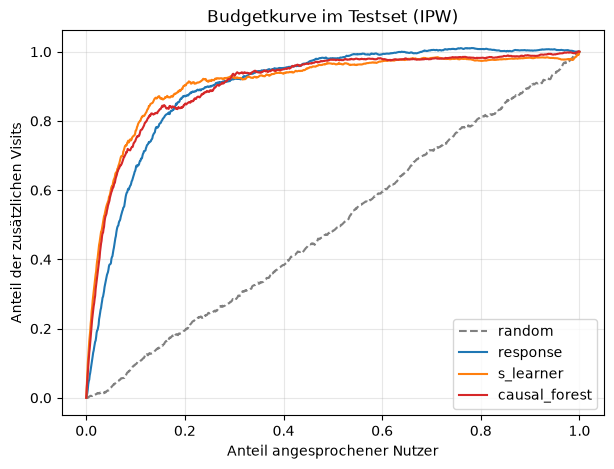

In [11]:
# Budgetkurve: Welcher Anteil der zusätzlichen Visits bleibt, wenn nur die Top-k angesprochen werden?
# 100 % = alle ansprechen
curves = {m: incremental_curve(y_te, w_te, preds[m], e_te)
          for m in ["random", "response", "s_learner", "causal_forest"]}
total = curves["s_learner"]["incremental"].iloc[-1]   # bei 100 % für alle Modelle gleich
COLORS = {"random": "grey", "response": "C0", "s_learner": "C1", "causal_forest": "C3"}   # wie in der Qini-Grafik

fig, ax = plt.subplots(figsize=(7, 5))
for m, c in curves.items():
    ax.plot(c["share"], c["incremental"] / total, label=m, color=COLORS[m], ls="--" if m == "random" else "-")
ax.set_xlabel("Anteil angesprochener Nutzer")
ax.set_ylabel("Anteil der zusätzlichen Visits")
ax.set_title("Budgetkurve im Testset (IPW)")
ax.grid(alpha=0.3)
ax.legend()
fig.savefig(FIG / "budget_curve.png", dpi=120, bbox_inches="tight")

at = [0.05, 0.1, 0.2, 0.3, 0.5]
pd.DataFrame({m: np.interp(at, c["share"], c["incremental"] / total) for m, c in curves.items()},
             index=pd.Index(at, name="angesprochen")).round(3)

In [12]:
# Annahmen (frei gewählt, nur zur Illustration):
VALUE_PER_VISIT = 0.50    # Wert eines zusätzlichen Visits in €
COST_PER_USER = 0.004     # Kosten, einen Nutzer anzusprechen, in € (≈ 4 € pro 1.000 Nutzer)
# Regel: ansprechen, wenn vorhergesagter Uplift × Wert > Kosten, also Uplift > Kosten / Wert
THRESHOLD = COST_PER_USER / VALUE_PER_VISIT
SCALE = 1e6 / N_TE        # Ergebnisse pro 1 Mio. Nutzer
print(f"Schwelle: Uplift > {THRESHOLD:.4f}")

def strategy(name, target):
    inc = incremental_visits(y_te, w_te, e_te, target)
    return {"strategie": name, "angesprochen": target.mean(),
            "zus_visits": inc * SCALE,
            "gewinn_eur": (VALUE_PER_VISIT * inc - COST_PER_USER * target.sum()) * SCALE}

rows = [strategy("niemand", ~everyone), strategy("alle", everyone)]
# Regelbasiert: nur möglich, wenn das Modell einen Uplift in absoluten Einheiten liefert
for m in UPLIFT_MODELS:
    rows.append(strategy(f"Regel: {m}", preds[m].to_numpy() > THRESHOLD))
# Zum Vergleich: der beste feste Anteil, im Nachhinein auf dem Testset gewählt (zu optimistisch)
for m in ["response", "s_learner"]:
    c = curves[m]
    profit = VALUE_PER_VISIT * c["incremental"] - COST_PER_USER * c["n_targeted"]
    best = c.loc[profit.idxmax()]
    rows.append({"strategie": f"bester Anteil im Nachhinein: {m}", "angesprochen": best["share"],
                 "zus_visits": best["incremental"] * SCALE, "gewinn_eur": profit.max() * SCALE})
policy = pd.DataFrame(rows).set_index("strategie")
policy.round({"angesprochen": 3, "zus_visits": 0, "gewinn_eur": 0})

Schwelle: Uplift > 0.0080


,angesprochen,zus_visits,gewinn_eur
strategie,,,
niemand,0.000,0.0,0.0
alle,1.000,7622.0,-189.0
Regel: s_learner,0.146,6612.0,2723.0
Regel: t_learner,0.154,6237.0,2502.0
Regel: x_learner,0.131,6181.0,2566.0
Regel: dr_learner,0.131,6108.0,2531.0
Regel: causal_forest,0.164,6396.0,2541.0
bester Anteil im Nachhinein: response,0.196,6639.0,2535.0
bester Anteil im Nachhinein: s_learner,0.141,6611.0,2742.0


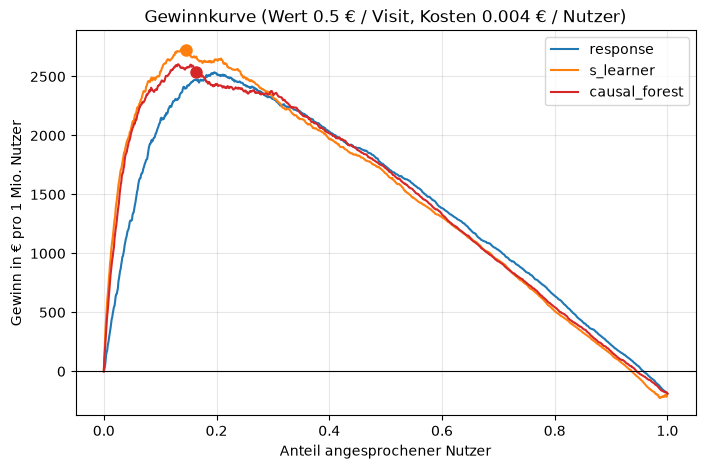

In [13]:
# Gewinnkurve: Gewinn je angesprochenem Anteil; Punkte = wohin die Regel "Uplift > Schwelle" führt
fig, ax = plt.subplots(figsize=(8, 5))
for m in ["response", "s_learner", "causal_forest"]:
    c = curves[m]
    ax.plot(c["share"], (VALUE_PER_VISIT * c["incremental"] - COST_PER_USER * c["n_targeted"]) * SCALE,
            label=m, color=COLORS[m])
    if m != "response":
        r = policy.loc[f"Regel: {m}"]
        ax.plot(r["angesprochen"], r["gewinn_eur"], "o", color=COLORS[m], ms=8)
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("Anteil angesprochener Nutzer")
ax.set_ylabel("Gewinn in € pro 1 Mio. Nutzer")
ax.set_title(f"Gewinnkurve (Wert {VALUE_PER_VISIT} € / Visit, Kosten {COST_PER_USER} € / Nutzer)")
ax.grid(alpha=0.3)
ax.legend()
fig.savefig(FIG / "profit_curve.png", dpi=120, bbox_inches="tight")

,alle,regel_s_learner,anteil_regel,bester_anteil_s_learner,bester_anteil_response
kosten_wert,,,,,
0.001000,6621.730,6717.056,0.345,6883.257,7029.287
0.001715,5906.428,6555.406,0.279,6618.267,6671.262
0.002942,4679.468,6268.046,0.226,6357.604,6170.909
0.005047,2574.861,5785.768,0.183,5919.846,5658.362
0.008657,-1035.177,5383.365,0.140,5390.623,4942.133
0.014849,-7227.483,4426.577,0.103,4542.781,3853.863
0.025471,-17849.161,3481.822,0.073,3539.818,2521.792
0.043690,-36068.550,2410.161,0.050,2439.544,1004.952


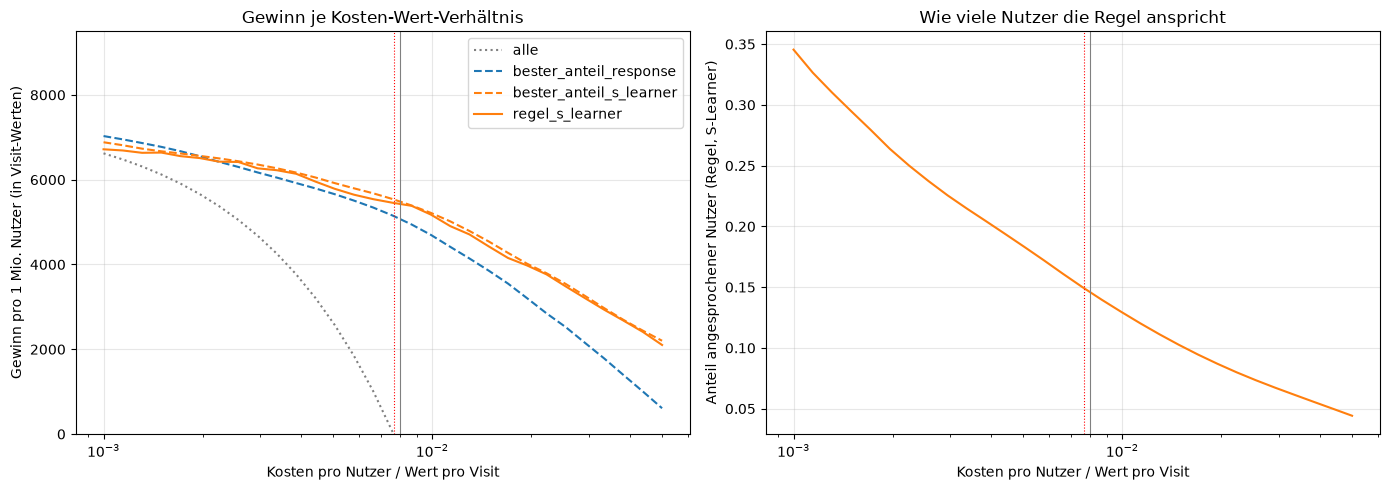

In [14]:
# Sensitivität: Das Ergebnis hängt nur vom Verhältnis Kosten / Wert ab → Gewinn in Einheiten "Wert eines Visits"
ratios = np.geomspace(0.001, 0.05, 30)
inc_all = incremental_visits(y_te, w_te, e_te, everyone)
s_score = preds["s_learner"].to_numpy()

sens = []
for r in ratios:
    target = s_score > r
    best = {m: (curves[m]["incremental"] - r * curves[m]["n_targeted"]).max() for m in ["response", "s_learner"]}
    sens.append({"kosten_wert": r,
                 "alle": (inc_all - r * N_TE) * SCALE,
                 "regel_s_learner": (incremental_visits(y_te, w_te, e_te, target) - r * target.sum()) * SCALE,
                 "anteil_regel": target.mean(),
                 "bester_anteil_s_learner": best["s_learner"] * SCALE,
                 "bester_anteil_response": best["response"] * SCALE})
sens = pd.DataFrame(sens).set_index("kosten_wert")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for col, color, ls in [("alle", "grey", ":"), ("bester_anteil_response", "C0", "--"),
                      ("bester_anteil_s_learner", "C1", "--"), ("regel_s_learner", "C1", "-")]:
    axes[0].plot(sens.index, sens[col], ls, color=color, label=col)
axes[0].set_ylim(0, None)   # Verluste ausgeblendet: dann spricht man besser niemanden an
axes[0].set_ylabel("Gewinn pro 1 Mio. Nutzer (in Visit-Werten)")
axes[0].set_title("Gewinn je Kosten-Wert-Verhältnis")
axes[1].plot(sens.index, sens["anteil_regel"], color="C1")
axes[1].set_ylabel("Anteil angesprochener Nutzer (Regel, S-Learner)")
axes[1].set_title("Wie viele Nutzer die Regel anspricht")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("Kosten pro Nutzer / Wert pro Visit")
    ax.axvline(THRESHOLD, color="grey", lw=0.8)              # gewählte Annahme
    ax.axvline(inc_all / N_TE, color="red", lw=0.8, ls=":")  # ab hier lohnt sich "alle" nicht mehr
    ax.grid(alpha=0.3)
axes[0].legend()
fig.tight_layout()
fig.savefig(FIG / "policy_sensitivity.png", dpi=120)

sens.iloc[::4].round(3)

In [15]:
policy.to_csv("../reports/policy_profit.csv")
sens.to_csv("../reports/policy_sensitivity.csv")